## Author: Gabriel Vance
## Class: DSC640 - Data Presentation & Visualization 
## Professor: Benjamin Schneider
## Date: October 3, 2025

# Purpose: This notebook performs the tasks for Week 3 & 4 assignment.

### Call to action: Transparency is important in politics. The public must be made aware of the visitors to the White House. To encourage this policy, we will be releasing reports explaining the trends of visitors to the White House over time.

In [20]:
import pandas as pd
import glob

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# Ensure that all code cells are fully visible without scrolling
from IPython.core.display import display, HTML

display(HTML('''
<style>
div.CodeMirror pre {
    white-space: pre !important;
}
</style>
'''))

In [21]:
# Read in all *.csv files
csv_files = glob.glob('*.csv')

dfs = [pd.read_csv(file) for file in csv_files]

In [22]:
# The column name is different, so let's examine each column name.
for file in csv_files:
    df_temp = pd.read_csv(file, nrows=0)
    print(f"{file}:")
    print(list(df_temp.columns))
    print('-')

2023.12_WAVES-ACCESS-RECORDS.csv:
['Last Name', 'First Name', 'Middle Initial', 'UIN', 'BDGNBR', 'Access Type', 'TOA', 'POA', 'TOD', 'POD', 'Appointment Made Date', 'Appointment Start Date', 'Appointment End Date', 'Appointment Cancel Date', 'Total People', 'Last Updated By', 'POST', 'Last Entry Date', 'Terminal Suffix', 'Visitee Last Name', 'Visitee First Name', 'Meeting Location', 'Meeting Room', 'Caller Last Name', 'Caller First Name', 'Caller Room', 'Release Date']
-
2022.09_WAVES-ACCESS-RECORDS.csv:
['Last Name', 'First Name', 'Middle Initial', 'UIN', 'BDGNBR', 'Access Type', 'TOA', 'POA', 'TOD', 'POD', 'Appointment Made Date', 'Appointment Start Date', 'Appointment End Date', 'Appointment Cancel Date', 'Total People', 'Last Updated By', 'POST', 'Last Entry Date', 'Terminal Suffix', 'Visitee Last Name', 'Visitee First Name', 'Meeting Location', 'Meeting Room', 'Caller Last Name', 'Caller First Name', 'CALLER_ROOM', 'RELEASEDATE']
-
2022.01_WAVES-ACCESS-RECORDS.csv:
['NAMELAST', 'N

In [23]:
total_rows = sum(len(df) for df in dfs)
print(f"Total number of rows in all CSVs: {total_rows}")

Total number of rows in all CSVs: 1207458


In [24]:
# Columns to keep 
columns_to_keep = ['last_name', 'first_name', 'appointment_start_date', 'total_people','meeting_room']

for df in dfs:
    if 'NAMELAST' in df.columns:
        df.rename(columns={'NAMELAST': 'last_name'}, inplace=True)
    if 'Last Name' in df.columns:
        df.rename(columns={'Last Name': 'last_name'}, inplace=True)
    if 'First Name' in df.columns:
        df.rename(columns={'First Name': 'first_name'}, inplace=True)
    if 'NAMEFIRST' in df.columns:
        df.rename(columns={'NAMEFIRST': 'first_name'}, inplace=True)
    if 'APPT_START_DATE' in df.columns:
        df.rename(columns={'APPT_START_DATE': 'appointment_start_date'}, inplace=True)
    if 'Appointment Start Date' in df.columns:
        df.rename(columns={'Appointment Start Date': 'appointment_start_date'}, inplace=True)
    if 'TOTAL_PEOPLE' in df.columns:
        df.rename(columns={'TOTAL_PEOPLE': 'total_people'}, inplace=True)
    if 'Total People' in df.columns:
        df.rename(columns={'Total People': 'total_people'}, inplace=True)
    if 'MEETING_ROOM' in df.columns:
        df.rename(columns={'MEETING_ROOM': 'meeting_room'}, inplace=True)
    if 'Meeting Room' in df.columns:
        df.rename(columns={'Meeting Room': 'meeting_room'}, inplace=True)

# Only keep dataframes that have all required columns
dfs_cleaned = [df[columns_to_keep] for df in dfs if all(col in df.columns for col in columns_to_keep)]

# Merge all cleaned dataframes into one
merged_df = pd.concat(dfs_cleaned, ignore_index=True)

# Sort by appointment_start_date
merged_df['appointment_start_date'] = pd.to_datetime(merged_df['appointment_start_date'], errors='coerce')
merged_df = merged_df.sort_values(by='appointment_start_date')

# Save the merged dataframe to CSV
merged_df.to_csv('merged_white_house_visitors_cleaned.csv', index=False)

In [25]:
merged_df

,last_name,first_name,appointment_start_date,total_people,meeting_room
648933,RIVERACENTENO,SARITA,2021-01-20 12:00:00,19.0,EW206
649004,VAUGHN,JAMES,2021-01-20 12:00:00,19.0,EW206
648998,TURNMIRE,BRIAN,2021-01-20 12:00:00,19.0,EW206
648750,FRANKE,CHRISTOPHER,2021-01-20 12:00:00,19.0,EW206
648743,FETTIG,JASON,2021-01-20 12:00:00,19.0,EW206
...,...,...,...,...,...
876086,KUKLISH,MATILDA,NaT,1.0,WW WHSR
876087,KUKLISH,MATILDA,NaT,1.0,WHSR
876088,JACKSON,KETANJI,NaT,1.0,205
876089,WILSON,BETH,NaT,1.0,188A


In [26]:
percent_nat = merged_df['appointment_start_date'].isna().mean() * 100
print(f"Percent of appointment_start_date that are NaT: {percent_nat:.2f}%")

Percent of appointment_start_date that are NaT: 3.42%


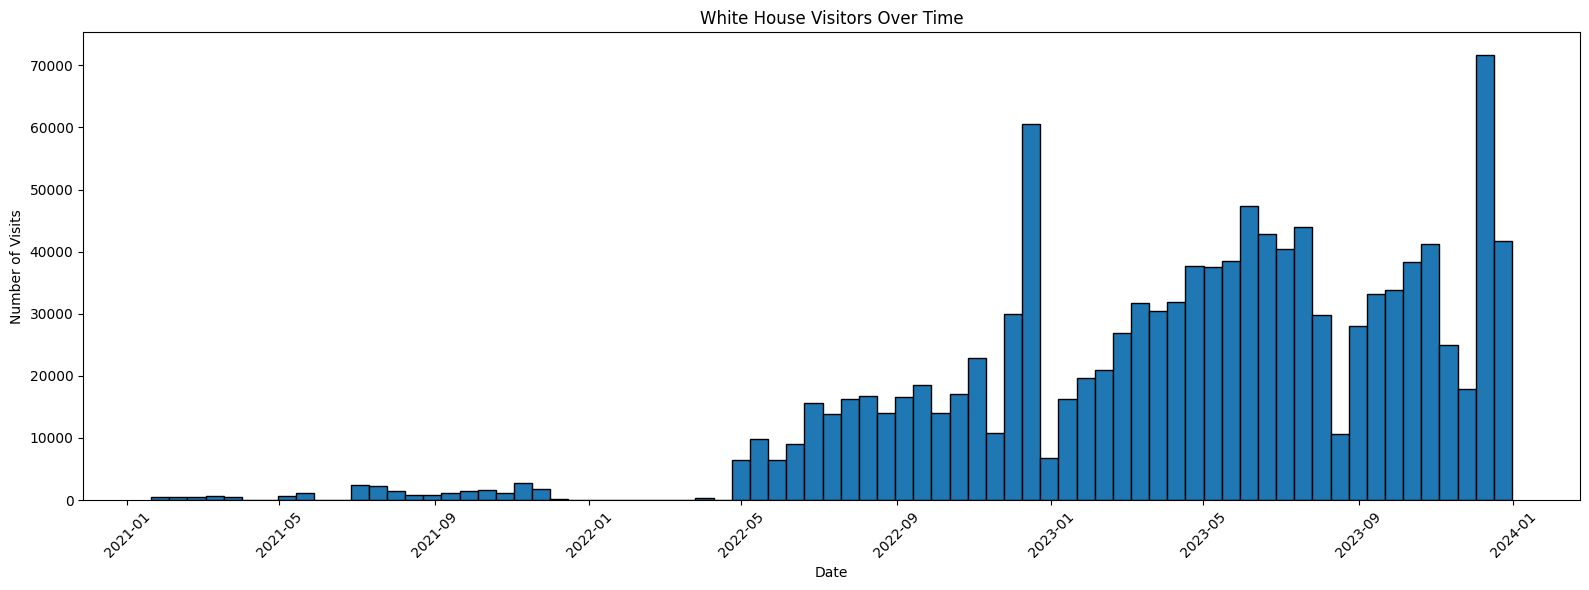

In [27]:
import matplotlib.pyplot as plt

# Group by date (ignore time) and count visits
visits_per_day = merged_df.dropna(subset=['appointment_start_date'])
visits_per_day = visits_per_day.groupby(merged_df['appointment_start_date'].dt.date).size()

plt.figure(figsize=(16,6))
plt.hist(visits_per_day.index, weights=visits_per_day.values, bins=75, edgecolor='black')
plt.xlabel('Date')
plt.ylabel('Number of Visits')
plt.title('White House Visitors Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### The transparency of the visits allows us to see the trend of visitors over times. This is the visitors to the White House from 2021 to 2023.